# 04 - Análise de Classificação

Objetivo: Prever `has_heart_disease` (Tem Doença Cardíaca: 0 ou 1)

Este é um problema de **classificação binária** - prever entre duas classes.

## Importar bibliotecas

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import chi2_contingency
import warnings
warnings.filterwarnings('ignore')

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)

## Carregar dados

In [2]:
df = pd.read_csv('../data/processed/dataset_classification.csv')
print(f"Dataset para classificação: {df.shape}")
print(f"\nPrimeiras linhas:")
print(df.head())

Dataset para classificação: (9000, 32)

Primeiras linhas:
   patient_id  age  sex  resting_bp_systolic  resting_bp_diastolic  \
0           1   44    1                  117                    74   
1           2   57    1                  139                    94   
2           3   29    1                  128                    78   
3           4   72    1                  132                    86   
4           5   62    0                  116                    75   

   cholesterol_total  hdl  ldl  triglycerides  fasting_blood_sugar  ...  \
0                193   57  106            119                  112  ...   
1                185   69  110             35                  114  ...   
2                197   52  108            157                   95  ...   
3                197   59  104            143                   92  ...   
4                154   65   75            104                  135  ...   

   daily_steps  diet_quality_score  has_heart_disease  \
0         773

## 1. Análise da Variável Alvo (Target)

In [3]:
target = 'has_heart_disease'

print(f"\n=== ANÁLISE DO TARGET: {target} ===")
print(f"\nDistribuição das classes:")
class_counts = df[target].value_counts().sort_index()
for label, count in class_counts.items():
    percentage = (count / len(df)) * 100
    disease_status = 'Com Doença' if label == 1 else 'Sem Doença'
    print(f"  {label} ({disease_status}): {count} pacientes ({percentage:.1f}%)")

print(f"\nEquilíbrio das classes:")
balance = class_counts.min() / class_counts.max()
print(f"  Taxa de balanceamento: {balance:.2%}")
if balance > 0.4:
    print(f"  ✓ Dataset relativamente balanceado")
else:
    print(f"  ⚠️ Dataset desbalanceado - considerar técnicas especiais")


=== ANÁLISE DO TARGET: has_heart_disease ===

Distribuição das classes:
  0 (Sem Doença): 6273 pacientes (69.7%)
  1 (Com Doença): 2727 pacientes (30.3%)

Equilíbrio das classes:
  Taxa de balanceamento: 43.47%
  ✓ Dataset relativamente balanceado


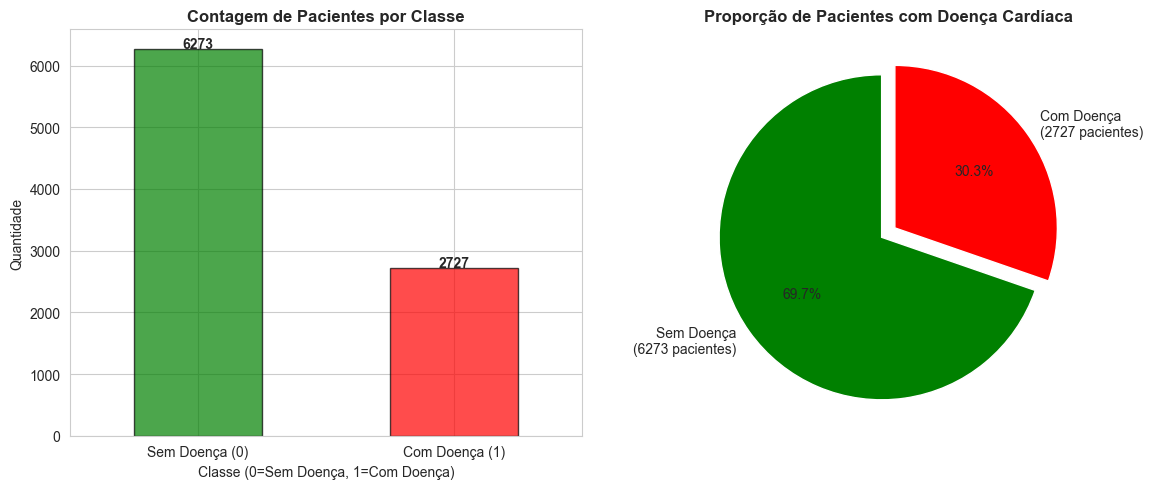

In [4]:
# Visualizar distribuição das classes
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Gráfico de barras
class_counts.plot(kind='bar', ax=axes[0], color=['green', 'red'], alpha=0.7, edgecolor='black')
axes[0].set_title('Contagem de Pacientes por Classe', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Classe (0=Sem Doença, 1=Com Doença)')
axes[0].set_ylabel('Quantidade')
axes[0].set_xticklabels(['Sem Doença (0)', 'Com Doença (1)'], rotation=0)
for i, v in enumerate(class_counts.values):
    axes[0].text(i, v + 10, str(v), ha='center', fontweight='bold')

# Gráfico de pizza
labels = [f'Sem Doença\n({class_counts[0]} pacientes)', 
          f'Com Doença\n({class_counts[1]} pacientes)']
axes[1].pie(class_counts.values, labels=labels, autopct='%1.1f%%', 
            colors=['green', 'red'], startangle=90, explode=(0.05, 0.05))
axes[1].set_title('Proporção de Pacientes com Doença Cardíaca', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

## 2. Análise de Características por Classe

In [5]:
# Comparar estatísticas por classe
print("\nEstatísticas das variáveis numéricas por classe:\n")

numericas = df.select_dtypes(include=[np.number]).columns
numericas = [col for col in numericas if col not in ['patient_id', target]]

for col in numericas[:6]:  # Primeiras 6 variáveis
    print(f"\n{col}:")
    print(f"  Sem doença - Média: {df[df[target]==0][col].mean():.2f}, Mediana: {df[df[target]==0][col].median():.2f}")
    print(f"  Com doença - Média: {df[df[target]==1][col].mean():.2f}, Mediana: {df[df[target]==1][col].median():.2f}")


Estatísticas das variáveis numéricas por classe:


age:
  Sem doença - Média: 51.48, Mediana: 52.00
  Com doença - Média: 59.72, Mediana: 60.00

sex:
  Sem doença - Média: 0.49, Mediana: 0.00
  Com doença - Média: 0.61, Mediana: 1.00

resting_bp_systolic:
  Sem doença - Média: 125.59, Mediana: 125.00
  Com doença - Média: 133.05, Mediana: 133.00

resting_bp_diastolic:
  Sem doença - Média: 79.40, Mediana: 79.00
  Com doença - Média: 83.99, Mediana: 84.00

cholesterol_total:
  Sem doença - Média: 185.19, Mediana: 186.00
  Com doença - Média: 196.95, Mediana: 197.00

hdl:
  Sem doença - Média: 57.27, Mediana: 57.00
  Com doença - Média: 50.49, Mediana: 51.00


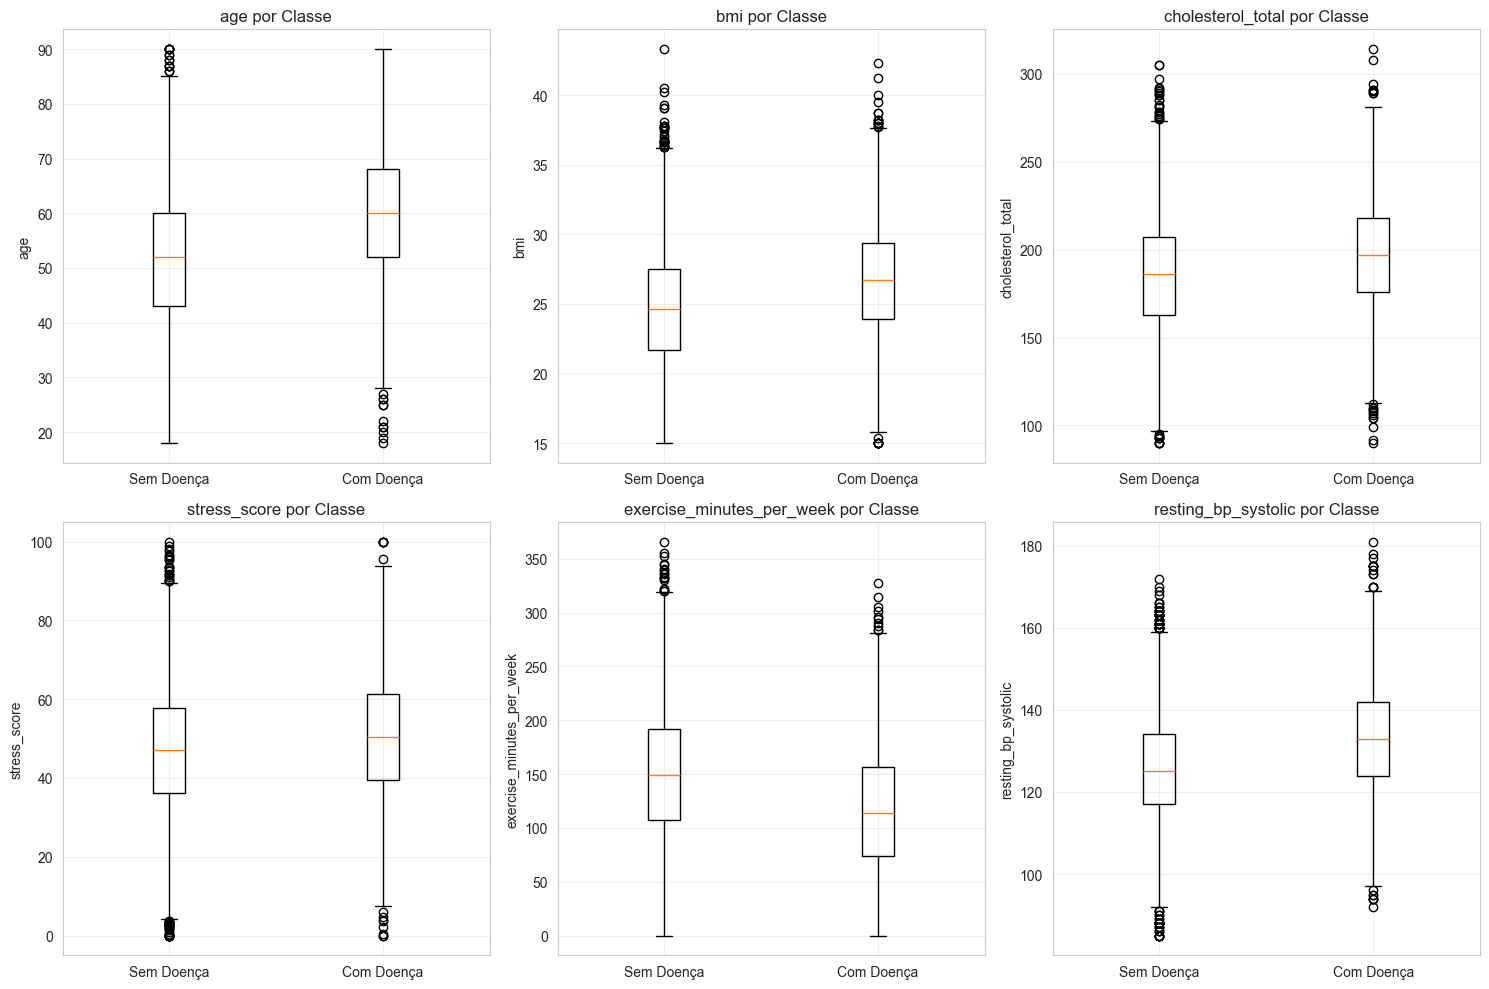

In [6]:
# Boxplots comparativos
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.flatten()

features_para_plot = ['age', 'bmi', 'cholesterol_total', 'stress_score', 'exercise_minutes_per_week', 'resting_bp_systolic']

for idx, feature in enumerate(features_para_plot):
    data_sem_doenca = df[df[target] == 0][feature]
    data_com_doenca = df[df[target] == 1][feature]
    
    axes[idx].boxplot([data_sem_doenca, data_com_doenca], labels=['Sem Doença', 'Com Doença'])
    axes[idx].set_ylabel(feature)
    axes[idx].set_title(f'{feature} por Classe')
    axes[idx].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 3. Poder Preditivo das Features

In [7]:
# Teste ANOVA para comparar grupos
from scipy.stats import f_oneway

print("\nTeste ANOVA (p-value < 0.05 = feature diferencia as classes):\n")

poder_preditivo = []

for col in numericas:
    sem_doenca = df[df[target] == 0][col].dropna()
    com_doenca = df[df[target] == 1][col].dropna()
    
    f_stat, p_value = f_oneway(sem_doenca, com_doenca)
    poder_preditivo.append({
        'Feature': col,
        'F-statistic': f_stat,
        'P-value': p_value,
        'Significante': 'Sim' if p_value < 0.05 else 'Não'
    })

anova_df = pd.DataFrame(poder_preditivo).sort_values('F-statistic', ascending=False)
print(anova_df.to_string(index=False))


Teste ANOVA (p-value < 0.05 = feature diferencia as classes):

                    Feature  F-statistic       P-value Significante
    max_heart_rate_achieved  4578.093223  0.000000e+00          Sim
    exercise_induced_angina  2226.934817  0.000000e+00          Sim
              st_depression  1312.751404 1.913158e-268          Sim
                        age   832.163850 4.290124e-175          Sim
                        ldl   691.532510 6.666104e-147          Sim
                        hdl   607.597877 7.065098e-130          Sim
        resting_bp_systolic   595.214900 2.364622e-127          Sim
  exercise_minutes_per_week   592.089550 1.026804e-126          Sim
                      hba1c   483.549338 1.963234e-104          Sim
                        bmi   428.679246  4.548192e-93          Sim
        fasting_blood_sugar   384.188777  8.393981e-84          Sim
       resting_bp_diastolic   348.524108  2.430486e-76          Sim
         resting_heart_rate   262.014870  4.113327e-

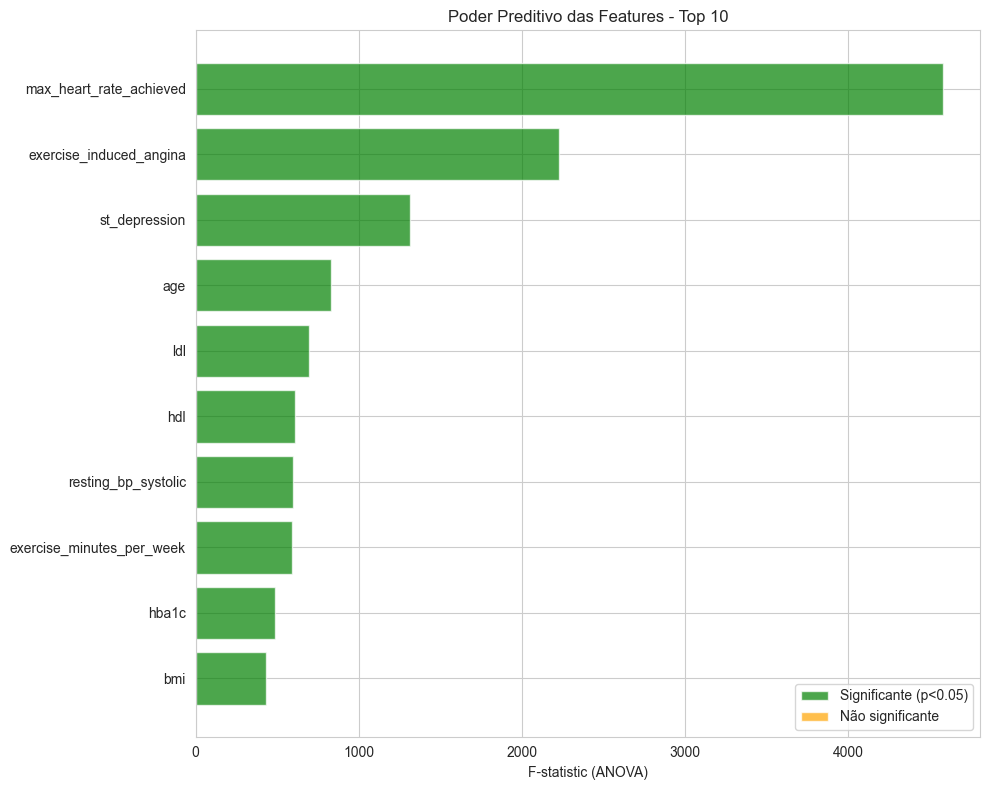

In [8]:
# Visualizar features mais importantes
fig, ax = plt.subplots(figsize=(10, 8))

top_features = anova_df.head(10)
colores = ['green' if x == 'Sim' else 'orange' for x in top_features['Significante']]

ax.barh(range(len(top_features)), top_features['F-statistic'].values, color=colores, alpha=0.7)
ax.set_yticks(range(len(top_features)))
ax.set_yticklabels(top_features['Feature'].values)
ax.set_xlabel('F-statistic (ANOVA)')
ax.set_title('Poder Preditivo das Features - Top 10')
ax.invert_yaxis()

# Adicionar legenda
from matplotlib.patches import Patch
legend_elements = [Patch(facecolor='green', alpha=0.7, label='Significante (p<0.05)'),
                   Patch(facecolor='orange', alpha=0.7, label='Não significante')]
ax.legend(handles=legend_elements, loc='lower right')

plt.tight_layout()
plt.show()

In [9]:
# Correlação ponto-bisserial com variáveis categóricas
from scipy.stats import pointbiserialr

print("\nCorrelação Ponto-Bisserial com Target (importância da feature):\n")

corr_features = []
for col in numericas:
    corr, p_value = pointbiserialr(df[target], df[col])
    corr_features.append({
        'Feature': col,
        'Correlação': corr,
        'P-value': p_value,
        'Abs_Correlação': abs(corr)
    })

corr_df = pd.DataFrame(corr_features).sort_values('Abs_Correlação', ascending=False)
print(corr_df[['Feature', 'Correlação', 'P-value']].head(10).to_string(index=False))


Correlação Ponto-Bisserial com Target (importância da feature):

                  Feature  Correlação       P-value
  max_heart_rate_achieved   -0.580704  0.000000e+00
  exercise_induced_angina    0.445412  0.000000e+00
            st_depression    0.356817 1.913158e-268
                      age    0.290954 4.290124e-175
                      ldl    0.267150 6.666104e-147
                      hdl   -0.251505 7.065098e-130
      resting_bp_systolic    0.249089 2.364622e-127
exercise_minutes_per_week   -0.248475 1.026804e-126
                    hba1c    0.225830 1.963234e-104
                      bmi    0.213249  4.548192e-93


## 4. Justificativa da Escolha da Variável Alvo

In [11]:
print("\n" + "="*70)
print(f"JUSTIFICATIVA: Por que {target} é uma boa variável para CLASSIFICAÇÃO")
print("="*70)

print(f"""
✓ VARIÁVEL CATEGÓRICA:
  - Tipo: Binária (0 ou 1)
  - Classe 0 (Sem Doença): {class_counts[0]} pacientes ({class_counts[0]/len(df)*100:.1f}%)
  - Classe 1 (Com Doença): {class_counts[1]} pacientes ({class_counts[1]/len(df)*100:.1f}%)
  - Balanceamento: {balance:.1%} (aceitável para classificação)

✓ RELEVÂNCIA CLÍNICA:
  - Classificação binária muito importante em saúde
  - Determina se paciente tem ou não risco de doença cardíaca
  - Resultado direto e interpretável: Sim ou Não

✓ DIFERENCIAÇÃO ENTRE CLASSES:
  - Múltiplas features diferenciam as duas classes significativamente
  - Há padrões diferentes entre pacientes saudáveis e com doença
  - Permite aprendizado supervisionado efetivo

✓ UTILIDADE PRÁTICA:
  - Pode servir para diagnóstico e triagem de pacientes
  - Ajuda na identificação de pessoas com alto risco
  - Permite intervenção precoce
""")


JUSTIFICATIVA: Por que has_heart_disease é uma boa variável para CLASSIFICAÇÃO

✓ VARIÁVEL CATEGÓRICA:
  - Tipo: Binária (0 ou 1)
  - Classe 0 (Sem Doença): 6273 pacientes (69.7%)
  - Classe 1 (Com Doença): 2727 pacientes (30.3%)
  - Balanceamento: 43.5% (aceitável para classificação)

✓ RELEVÂNCIA CLÍNICA:
  - Classificação binária muito importante em saúde
  - Determina se paciente tem ou não risco de doença cardíaca
  - Resultado direto e interpretável: Sim ou Não

✓ DIFERENCIAÇÃO ENTRE CLASSES:
  - Múltiplas features diferenciam as duas classes significativamente
  - Há padrões diferentes entre pacientes saudáveis e com doença
  - Permite aprendizado supervisionado efetivo

✓ UTILIDADE PRÁTICA:
  - Pode servir para diagnóstico e triagem de pacientes
  - Ajuda na identificação de pessoas com alto risco
  - Permite intervenção precoce



## 5. Recomendações para Modelagem

In [12]:
top_5_features = corr_df['Feature'].head(5).tolist()

print("\n" + "="*70)
print("RECOMENDAÇÕES PARA MODELAGEM DE CLASSIFICAÇÃO")
print("="*70)

print(f"""
📊 CARACTERÍSTICAS DO PROBLEMA:
  - Tipo: Classificação Binária
  - Target: has_heart_disease (0 ou 1)
  - Número de samples: {len(df)}
  - Número de features: {len(numericas)}
  - Balanceamento: {balance:.1%}

🎯 TOP 5 FEATURES RECOMENDADAS:
""")
for i, (_, row) in enumerate(corr_df.head(5).iterrows(), 1):
    print(f"  {i}. {row['Feature']} (correlação: {row['Correlação']:.3f})")

print(f"""
⚠️ POSSÍVEIS DESAFIOS:
  • Desbalanceamento moderado de classes
    → Considerar estratificação em validação cruzada
    → Ajustar class_weight em modelos
  • Múltiplas features correlacionadas entre si
    → Pode indicar multicolinearidade
    → Feature selection pode ajudar

🤖 ALGORITMOS RECOMENDADOS PARA TESTAR:
  
  SIMPLES (interpretáveis):
  ✓ Logistic Regression - rápido, interpretável
  ✓ Naive Bayes - bom baseline
  ✓ KNN (k-Nearest Neighbors) - não-paramétrico
  
  INTERMEDIÁRIO (melhor desempenho):
  ✓ Decision Tree - interpretável, captura não-linearidade
  ✓ Random Forest - robusto, liida bem com features múltiplas
  ✓ SVM (Support Vector Machine) - excelente para classificação
  
  AVANÇADO (máximo desempenho):
  ✓ Gradient Boosting (XGBoost, LightGBM) - estado da arte
  ✓ Neural Networks - se data for suficiente

💡 DICAS DE IMPLEMENTAÇÃO:
  • Usar cross-validation (estratificada) para avaliação
  • Métricas importantes: Accuracy, Precision, Recall, F1-score, AUC-ROC
  • Matriz de confusão para entender tipos de erro
  • Para desbalanceamento: considerar SMOTE ou class_weight
  • Threshold de decisão pode ser ajustado conforme necessário

⚖️ TRADE-OFFS:
  • Precision vs Recall: Depende do custo de falsos positivos/negativos
  • Em diagnóstico: geralmente preferir Recall (não perder doentes)
  • Usar AUC-ROC para comparação justa entre modelos
""")


RECOMENDAÇÕES PARA MODELAGEM DE CLASSIFICAÇÃO

📊 CARACTERÍSTICAS DO PROBLEMA:
  - Tipo: Classificação Binária
  - Target: has_heart_disease (0 ou 1)
  - Número de samples: 9000
  - Número de features: 30
  - Balanceamento: 43.5%

🎯 TOP 5 FEATURES RECOMENDADAS:

  1. max_heart_rate_achieved (correlação: -0.581)
  2. exercise_induced_angina (correlação: 0.445)
  3. st_depression (correlação: 0.357)
  4. age (correlação: 0.291)
  5. ldl (correlação: 0.267)

⚠️ POSSÍVEIS DESAFIOS:
  • Desbalanceamento moderado de classes
    → Considerar estratificação em validação cruzada
    → Ajustar class_weight em modelos
  • Múltiplas features correlacionadas entre si
    → Pode indicar multicolinearidade
    → Feature selection pode ajudar

🤖 ALGORITMOS RECOMENDADOS PARA TESTAR:

  SIMPLES (interpretáveis):
  ✓ Logistic Regression - rápido, interpretável
  ✓ Naive Bayes - bom baseline
  ✓ KNN (k-Nearest Neighbors) - não-paramétrico

  INTERMEDIÁRIO (melhor desempenho):
  ✓ Decision Tree - interpret

## 6. Próximos Passos

In [13]:
print("""
✅ ANÁLISE EXPLORATÓRIA COMPLETADA

Próximos passos (não inclusos nesta análise):

1. PREPROCESSAMENTO AVANÇADO:
   - Feature scaling/normalization
   - Tratamento de desbalanceamento (SMOTE)
   - Feature selection/engineering

2. VALIDAÇÃO:
   - Split treino/teste
   - Cross-validation estratificada
   - Hyperparameter tuning

3. MODELAGEM:
   - Treinar diferentes algoritmos
   - Comparar desempenho
   - Otimizar para métrica apropriada

4. AVALIAÇÃO:
   - Análise de erros
   - Importância de features
   - Interpretabilidade do modelo

5. DEPLOYMENT:
   - Selecionar melhor modelo
   - Documentar decisões
   - Preparar para produção
""")


✅ ANÁLISE EXPLORATÓRIA COMPLETADA

Próximos passos (não inclusos nesta análise):

1. PREPROCESSAMENTO AVANÇADO:
   - Feature scaling/normalization
   - Tratamento de desbalanceamento (SMOTE)
   - Feature selection/engineering

2. VALIDAÇÃO:
   - Split treino/teste
   - Cross-validation estratificada
   - Hyperparameter tuning

3. MODELAGEM:
   - Treinar diferentes algoritmos
   - Comparar desempenho
   - Otimizar para métrica apropriada

4. AVALIAÇÃO:
   - Análise de erros
   - Importância de features
   - Interpretabilidade do modelo

5. DEPLOYMENT:
   - Selecionar melhor modelo
   - Documentar decisões
   - Preparar para produção

